## Why Cache-Aware Evaluation Is Required

Standard perplexity evaluation performs normal forward passes and does not require reuse of the KV cache. Therefore, it cannot measure the effect of KV-cache quantization.

To evaluate KV-cache compression correctly, the quantized/dequantized Key and Value tensors must be reused when predicting subsequent tokens. In the cache-aware evaluation, previous K/V states are stored in the cache, modified according to the selected precision, and then reused during future attention computations.

This separates two aspects of the experiment:

* **Memory model** $\rightarrow$ theoretical INT8/packed-INT4 storage
* **Quality model** $\rightarrow$ predictions made using quantized/dequantized cached K/V

Perplexity can then measure whether the memory savings actually degrade language-model quality.

#1. Setup + WikiText-2 sanity sequence

In [1]:
# Install dependencies
!pip -q install -U transformers accelerate safetensors datasets

import torch
import pandas as pd
import numpy as np
import math

from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset


# --------------------------------------------------
# Configuration
# --------------------------------------------------

MODEL_ID = "Qwen/Qwen2.5-1.5B"
DTYPE = torch.float16

PAGE_SIZE = 16

# Small natural-text sequence used first to validate
# the cache-aware evaluator.
SANITY_EVAL_TOKENS = 2048


# --------------------------------------------------
# GPU
# --------------------------------------------------

print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU runtime required.")

gpu = torch.cuda.get_device_properties(0)

print("GPU:", gpu.name)
print(f"VRAM: {gpu.total_memory / 1024**3:.2f} GiB")


# --------------------------------------------------
# Load model
# --------------------------------------------------

print("\nLoading:", MODEL_ID)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
    device_map={"": 0},
    low_cpu_mem_usage=True,
    attn_implementation="sdpa",
)

model.eval()


# --------------------------------------------------
# Load WikiText-2 test set
# --------------------------------------------------

test_dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1",
    split="test"
)

test_text = "\n\n".join(
    test_dataset["text"]
)


# --------------------------------------------------
# Tokenize
# --------------------------------------------------

encodings = tokenizer(
    test_text,
    return_tensors="pt",
    add_special_tokens=False
)

all_test_ids = encodings.input_ids

sanity_input_ids = all_test_ids[
    :, :SANITY_EVAL_TOKENS
].to(model.device)


# --------------------------------------------------
# Print setup
# --------------------------------------------------

print("\nWikiText-2 test rows:", len(test_dataset))
print("Full test tokens:", all_test_ids.shape[1])

print("\nSanity evaluation tokens:", sanity_input_ids.shape[1])
print("Input shape:", tuple(sanity_input_ids.shape))

print("Page size:", PAGE_SIZE)

print(
    "Number of page-sized chunks:",
    math.ceil(
        SANITY_EVAL_TOKENS / PAGE_SIZE
    )
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 60.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 14.9 MB/s eta 0:00:00
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GiB

Loading: Qwen/Qwen2.5-1.5B


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors



WikiText-2 test rows: 4358
Full test tokens: 299078

Sanity evaluation tokens: 2048
Input shape: (1, 2048)
Page size: 16
Number of page-sized chunks: 128


#2. Safely copy and quantize a DynamicCache

Safe Cache Quantization

Each experimental precision must use an independent KV cache. The original FP16 cache is never modified in place. Instead, a new DynamicCache is created and populated with either exact FP16 copies or quantized/dequantized approximations.

Quantization is performed independently for every transformer layer, every 16-token page, and separately for Key and Value tensors. Therefore:

s=s(l,p,K/V)

rather than using one global scale for the entire cache. This preserves the per-layer, per-page quantization scheme established in the uniform quantization baseline.

In [2]:
from transformers import DynamicCache


# --------------------------------------------------
# Symmetric quantization
# --------------------------------------------------

def symmetric_quantize(tensor, num_bits):

    if num_bits not in [4, 8]:
        raise ValueError("num_bits must be 4 or 8")

    qmax = (2 ** (num_bits - 1)) - 1
    qmin = -qmax

    x = tensor.float()

    max_abs = x.abs().max()

    if max_abs.item() == 0:
        scale = torch.tensor(
            1.0,
            device=tensor.device,
            dtype=torch.float32
        )
    else:
        scale = max_abs / qmax

    q = torch.round(x / scale)

    q = torch.clamp(
        q,
        qmin,
        qmax
    )

    q = q.to(torch.int8)

    return q, scale


def symmetric_dequantize(
    q_tensor,
    scale,
    dtype=torch.float16
):

    return (
        q_tensor.float() * scale
    ).to(dtype)


# --------------------------------------------------
# Quantize one tensor page-by-page
# --------------------------------------------------

def quantize_tensor_by_pages(
    tensor,
    num_bits,
    page_size
):

    reconstructed = torch.empty_like(tensor)

    seq_len = tensor.shape[2]

    scales = []

    for start in range(0, seq_len, page_size):

        end = min(
            start + page_size,
            seq_len
        )

        page = tensor[
            :, :, start:end, :
        ]

        q_page, scale = symmetric_quantize(
            page,
            num_bits
        )

        dq_page = symmetric_dequantize(
            q_page,
            scale,
            dtype=tensor.dtype
        )

        reconstructed[
            :, :, start:end, :
        ] = dq_page

        scales.append(scale.item())

    return reconstructed, scales


# --------------------------------------------------
# Create an independent cache
# --------------------------------------------------

def copy_and_quantize_cache(
    source_cache,
    num_bits=None,
    page_size=PAGE_SIZE
):
    """
    num_bits=None -> exact FP16 copy
    num_bits=8    -> INT8 quantize/dequantize
    num_bits=4    -> INT4 quantize/dequantize
    """

    new_cache = DynamicCache(
        config=model.config
    )

    all_scales = []

    for layer_idx, layer in enumerate(
        source_cache.layers
    ):

        source_k = layer.keys
        source_v = layer.values


        # ------------------------------------------
        # Exact FP16 copy
        # ------------------------------------------

        if num_bits is None:

            new_k = source_k.clone()
            new_v = source_v.clone()

            layer_scales = None


        # ------------------------------------------
        # Quantized/dequantized copy
        # ------------------------------------------

        else:

            new_k, k_scales = (
                quantize_tensor_by_pages(
                    source_k,
                    num_bits,
                    page_size
                )
            )

            new_v, v_scales = (
                quantize_tensor_by_pages(
                    source_v,
                    num_bits,
                    page_size
                )
            )

            layer_scales = {
                "key": k_scales,
                "value": v_scales
            }


        # Add this layer to the independent cache
        new_cache.update(
            new_k,
            new_v,
            layer_idx
        )

        all_scales.append(
            layer_scales
        )


    return new_cache, all_scales

In [3]:
# --------------------------------------------------
# Small safety test
# --------------------------------------------------

test_ids = sanity_input_ids[:, :32]

with torch.inference_mode():

    test_outputs = model(
        input_ids=test_ids,
        use_cache=True
    )

original_cache = test_outputs.past_key_values


# Exact independent copy
fp16_copy, _ = copy_and_quantize_cache(
    original_cache,
    num_bits=None
)


# INT8 copy
int8_copy, int8_scales = copy_and_quantize_cache(
    original_cache,
    num_bits=8
)


# INT4 copy
int4_copy, int4_scales = copy_and_quantize_cache(
    original_cache,
    num_bits=4
)


# --------------------------------------------------
# Validate
# --------------------------------------------------

original_k = original_cache.layers[0].keys
copied_k = fp16_copy.layers[0].keys
int8_k = int8_copy.layers[0].keys
int4_k = int4_copy.layers[0].keys


print("Original cache length:",
      original_cache.get_seq_length())

print("FP16-copy length:",
      fp16_copy.get_seq_length())

print("INT8-copy length:",
      int8_copy.get_seq_length())

print("INT4-copy length:",
      int4_copy.get_seq_length())


print("\nFP16 copy exactly equal:",
      torch.equal(
          original_k,
          copied_k
      ))


print(
    "FP16 copy shares storage:",
    original_k.data_ptr()
    == copied_k.data_ptr()
)


print(
    "\nINT8 mean absolute difference:",
    (
        original_k.float()
        - int8_k.float()
    ).abs().mean().item()
)


print(
    "INT4 mean absolute difference:",
    (
        original_k.float()
        - int4_k.float()
    ).abs().mean().item()
)

Original cache length: 32
FP16-copy length: 32
INT8-copy length: 32
INT4-copy length: 32

FP16 copy exactly equal: True
FP16 copy shares storage: False

INT8 mean absolute difference: 0.6054689884185791
INT4 mean absolute difference: 3.50382137298584


Cache-Copy Validation

Independent FP16, INT8, and INT4 cache copies were successfully created. The FP16 copy was exactly equal to the original cache while occupying separate tensor storage, ensuring that experiments cannot modify one another. As expected, INT4 introduced substantially more reconstruction error than INT8.

#3. Validate cache-aware FP16 inference

In [4]:
import torch.nn.functional as F


# --------------------------------------------------
# Validation configuration
# --------------------------------------------------

VALIDATION_TOKENS = 256
CHUNK_SIZE = PAGE_SIZE   # 16 tokens

validation_ids = sanity_input_ids[
    :, :VALIDATION_TOKENS
]

print("Validation shape:", tuple(validation_ids.shape))
print("Chunk size:", CHUNK_SIZE)
print(
    "Number of chunks:",
    math.ceil(VALIDATION_TOKENS / CHUNK_SIZE)
)


# ==================================================
# METHOD A: Normal full FP16 forward pass
# ==================================================

with torch.inference_mode():

    full_outputs = model(
        input_ids=validation_ids,
        use_cache=False
    )

full_logits = full_outputs.logits


# Full-sequence next-token loss
full_loss_sum = F.cross_entropy(
    full_logits[:, :-1, :].float().reshape(
        -1,
        full_logits.shape[-1]
    ),
    validation_ids[:, 1:].reshape(-1),
    reduction="sum"
).item()

num_target_tokens = VALIDATION_TOKENS - 1

full_nll = (
    full_loss_sum / num_target_tokens
)

full_ppl = math.exp(full_nll)


# ==================================================
# METHOD B: Chunked FP16 cache-aware forward
# ==================================================

cache = DynamicCache(
    config=model.config
)

cached_loss_sum = 0.0
cached_target_tokens = 0

max_logit_diff = 0.0
sum_abs_logit_diff = 0.0
num_logit_values = 0

same_top1 = 0
num_prediction_positions = 0


for start in range(
    0,
    VALIDATION_TOKENS,
    CHUNK_SIZE
):

    end = min(
        start + CHUNK_SIZE,
        VALIDATION_TOKENS
    )

    chunk_ids = validation_ids[
        :, start:end
    ]


    # ----------------------------------------------
    # Explicit positions in the accumulated cache
    # ----------------------------------------------

    cache_position = torch.arange(
        start,
        end,
        device=model.device
    )


    # Attention mask covers:
    # previous cache + current chunk
    attention_mask = torch.ones(
        (1, end),
        dtype=torch.long,
        device=model.device
    )


    # ----------------------------------------------
    # Cached forward
    # ----------------------------------------------

    with torch.inference_mode():

        chunk_outputs = model(
            input_ids=chunk_ids,
            past_key_values=cache,
            attention_mask=attention_mask,
            cache_position=cache_position,
            use_cache=True
        )


    cache = chunk_outputs.past_key_values

    chunk_logits = chunk_outputs.logits


    # ==================================================
    # Compare logits with full forward
    # ==================================================

    reference_logits = full_logits[
        :, start:end, :
    ]

    diff = (
        chunk_logits.float()
        - reference_logits.float()
    ).abs()

    max_logit_diff = max(
        max_logit_diff,
        diff.max().item()
    )

    sum_abs_logit_diff += (
        diff.sum().item()
    )

    num_logit_values += diff.numel()


    # ==================================================
    # Compare top-1 predictions
    # ==================================================

    cached_pred = chunk_logits.argmax(
        dim=-1
    )

    full_pred = reference_logits.argmax(
        dim=-1
    )

    same_top1 += (
        cached_pred == full_pred
    ).sum().item()

    num_prediction_positions += (
        cached_pred.numel()
    )


    # ==================================================
    # Next-token loss
    #
    # Logit at global position t predicts token t+1.
    # ==================================================

    num_valid_predictions = min(
        end,
        VALIDATION_TOKENS - 1
    ) - start

    if num_valid_predictions > 0:

        logits_for_loss = chunk_logits[
            :, :num_valid_predictions, :
        ]

        targets = validation_ids[
            :,
            start + 1:
            start + 1 + num_valid_predictions
        ]

        loss_sum = F.cross_entropy(
            logits_for_loss.float().reshape(
                -1,
                logits_for_loss.shape[-1]
            ),
            targets.reshape(-1),
            reduction="sum"
        )

        cached_loss_sum += (
            loss_sum.item()
        )

        cached_target_tokens += (
            targets.numel()
        )


# ==================================================
# Final statistics
# ==================================================

cached_nll = (
    cached_loss_sum
    / cached_target_tokens
)

cached_ppl = math.exp(
    cached_nll
)

mean_logit_diff = (
    sum_abs_logit_diff
    / num_logit_values
)

top1_agreement = (
    same_top1
    / num_prediction_positions
)


print("\nFP16 Cache-Aware Validation")
print("---------------------------")

print(
    "Final cache length:",
    cache.get_seq_length()
)

print(
    "Reference target tokens:",
    num_target_tokens
)

print(
    "Cached target tokens:",
    cached_target_tokens
)

print("\nLogit comparison")
print(
    f"Mean absolute difference: "
    f"{mean_logit_diff:.8f}"
)
print(
    f"Maximum absolute difference: "
    f"{max_logit_diff:.8f}"
)
print(
    f"Top-1 agreement: "
    f"{100 * top1_agreement:.2f}%"
)

print("\nQuality comparison")
print(
    f"Full FP16 NLL:   {full_nll:.6f}"
)
print(
    f"Cached FP16 NLL: {cached_nll:.6f}"
)

print(
    f"Full FP16 PPL:   {full_ppl:.6f}"
)
print(
    f"Cached FP16 PPL: {cached_ppl:.6f}"
)

print(
    f"PPL difference:  "
    f"{abs(full_ppl - cached_ppl):.6f}"
)

Validation shape: (1, 256)
Chunk size: 16
Number of chunks: 16

FP16 Cache-Aware Validation
---------------------------
Final cache length: 256
Reference target tokens: 255
Cached target tokens: 255

Logit comparison
Mean absolute difference: 0.00523690
Maximum absolute difference: 0.16406250
Top-1 agreement: 99.61%

Quality comparison
Full FP16 NLL:   2.497412
Cached FP16 NLL: 2.497694
Full FP16 PPL:   12.151011
Cached FP16 PPL: 12.154431
PPL difference:  0.003421


**FP16 Cache-Aware Evaluation Validation**

Before evaluating quantized KV caches, the cache-aware inference procedure was validated against a normal full FP16 forward pass. The same 256-token WikiText-2 sequence was evaluated using two methods:

* **Full forward pass:** A single, complete forward pass across the full sequence.
* **Chunked inference:** 16-token chunked inference reusing the accumulated KV cache.

The loss was computed manually using global next-token targets so that predictions crossing chunk boundaries were not lost. Therefore, all $256 - 1 = 255$ predictable tokens were evaluated exactly once.

---

**Results**

The two methods produced nearly identical results:

* **Perplexity:**

$$\text{PPL}_{\text{full}} = 12.1510 \quad \text{vs.} \quad \text{PPL}_{\text{cached}} = 12.1544$$



*(Perplexity difference: 0.0034)*
* **Logit Difference (Mean Absolute):** 0.00524
* **Top-1 Prediction Agreement:** 99.61%

---

These results confirm that the chunked cache-aware evaluation closely reproduces normal FP16 inference and can therefore be used to measure the effect of KV-cache quantization.

#4. Cache-aware INT8 and INT4 sanity test

**Page Quantization During Autoregressive Inference**

The KV cache is constructed incrementally in fixed-size pages of 16 tokens. While the current page is being generated, its KV values remain in FP16. Once the page is complete, it is quantized and dequantized exactly once, and the reconstructed values replace the original FP16 values in the cache.

* **Example Lifecycle (Tokens 0–15):**
1. **Generation:** Page 0 generated in FP16.
2. **Compression:** Quantized and dequantized once:

$$\text{KV}_{0:15}^{\text{FP16}} \longrightarrow \text{KV}_{0:15}^{\text{INT}b} \longrightarrow \text{KV}_{0:15}^{\text{FP16}}$$



*(where $b \in \{4, 8\}$)*
3. **Reuse:** When processing tokens 16–31, the model attends to the reconstructed $\text{KV}_{0:15}$ page instead of the original FP16 states.
4. **Subsequent Pages:** After Page 1 completes, it is compressed in the same way.



---

* **Key Principles:**
* **No Re-Quantization:** Previously compressed pages are never re-quantized. Re-quantizing old pages at every step would artificially accumulate error instead of modeling a cache stored once at a set precision.
* **Simulation Flow:**
$$\text{Create Page (FP16)} \longrightarrow \text{Compress Once} \longrightarrow \text{Reuse Compressed Approximation}$$


* **Implementation:** Reconstructed cache pages are stored as FP16 tensors for compatibility with standard attention kernels, but their values carry the exact approximation error of the target INT8 or INT4 representation.

PyTorch Inference-Mode Cache Updates

KV-cache tensors produced inside torch.inference_mode() are inference tensors. PyTorch prevents these tensors from being modified in-place outside inference mode. Since cache quantization intentionally replaces newly completed KV pages with their quantized/dequantized approximations, the cache update is also performed inside torch.inference_mode(). This is an implementation constraint and does not change the quantization algorithm.

In [8]:
# ============================================================
# CELL 4 — Cache-aware INT8 / INT4 sanity evaluation
# ============================================================

import torch
import torch.nn.functional as F
import pandas as pd
import math

from transformers import DynamicCache


# --------------------------------------------------
# Quantize only a newly completed cache page
# --------------------------------------------------

def quantize_cache_range_inplace(
    cache,
    start_token,
    end_token,
    num_bits
):
    """
    Quantize/dequantize one token range in every
    transformer layer.

    Quantization is independent for:
      - every layer
      - every page
      - Key and Value separately

    The dequantized values are written back into
    the cache so future chunks use the approximated
    KV values.
    """

    scales = []

    for layer_idx, layer in enumerate(cache.layers):

        # ------------------------------------------
        # Extract the newly completed page
        # ------------------------------------------

        key_page = layer.keys[
            :, :, start_token:end_token, :
        ]

        value_page = layer.values[
            :, :, start_token:end_token, :
        ]


        # ------------------------------------------
        # Quantize K and V independently
        # ------------------------------------------

        q_key, key_scale = symmetric_quantize(
            key_page,
            num_bits
        )

        q_value, value_scale = symmetric_quantize(
            value_page,
            num_bits
        )


        # ------------------------------------------
        # Dequantize back to the original dtype
        #
        # The cache remains compatible with the
        # normal FP16 attention implementation.
        # ------------------------------------------

        dq_key = symmetric_dequantize(
            q_key,
            key_scale,
            dtype=layer.keys.dtype
        )

        dq_value = symmetric_dequantize(
            q_value,
            value_scale,
            dtype=layer.values.dtype
        )


        # ------------------------------------------
        # Replace ONLY this newly completed page
        # ------------------------------------------

        layer.keys[
            :, :, start_token:end_token, :
        ] = dq_key

        layer.values[
            :, :, start_token:end_token, :
        ] = dq_value


        scales.append({
            "layer": layer_idx,
            "key_scale": key_scale.item(),
            "value_scale": value_scale.item()
        })

    return scales


# --------------------------------------------------
# Cache-aware evaluation with uniform quantization
# --------------------------------------------------

def evaluate_quantized_cache(
    input_ids,
    num_bits,
    chunk_size=PAGE_SIZE
):

    seq_len = input_ids.shape[1]

    # Independent empty cache for this experiment
    cache = DynamicCache(
        config=model.config
    )

    total_loss = 0.0
    total_targets = 0

    total_abs_logit_diff = 0.0
    total_logit_values = 0
    quant_max_logit_diff = 0.0

    same_top1 = 0
    total_prediction_positions = 0


    # ==================================================
    # Process sequence page/chunk by page/chunk
    # ==================================================

    for start in range(
        0,
        seq_len,
        chunk_size
    ):

        end = min(
            start + chunk_size,
            seq_len
        )

        chunk_ids = input_ids[
            :, start:end
        ]


        # ------------------------------------------
        # Absolute positions of current tokens
        # ------------------------------------------

        cache_position = torch.arange(
            start,
            end,
            device=model.device
        )


        # ------------------------------------------
        # Attention mask covers:
        #
        # previous cached tokens
        # +
        # current chunk
        # ------------------------------------------

        attention_mask = torch.ones(
            (input_ids.shape[0], end),
            dtype=torch.long,
            device=model.device
        )


        # ------------------------------------------
        # Forward pass
        #
        # Previous pages already contain their
        # quantized/dequantized approximations.
        # ------------------------------------------

        with torch.inference_mode():

            outputs = model(
                input_ids=chunk_ids,
                past_key_values=cache,
                attention_mask=attention_mask,
                cache_position=cache_position,
                use_cache=True
            )


        cache = outputs.past_key_values

        chunk_logits = outputs.logits


        # ==================================================
        # Compare against normal FP16 logits from Cell 3
        # ==================================================

        reference_logits = full_logits[
            :, start:end, :
        ]

        diff = (
            chunk_logits.float()
            - reference_logits.float()
        ).abs()

        total_abs_logit_diff += (
            diff.sum().item()
        )

        total_logit_values += (
            diff.numel()
        )

        quant_max_logit_diff = max(
            quant_max_logit_diff,
            diff.max().item()
        )


        # ==================================================
        # Top-1 prediction agreement with FP16
        # ==================================================

        quant_pred = chunk_logits.argmax(
            dim=-1
        )

        fp16_pred = reference_logits.argmax(
            dim=-1
        )

        same_top1 += (
            quant_pred == fp16_pred
        ).sum().item()

        total_prediction_positions += (
            quant_pred.numel()
        )


        # ==================================================
        # Global next-token loss
        #
        # Logit at global position t predicts token t+1.
        # This also preserves predictions crossing page
        # boundaries.
        # ==================================================

        num_valid_predictions = (
            min(end, seq_len - 1)
            - start
        )

        if num_valid_predictions > 0:

            logits_for_loss = chunk_logits[
                :, :num_valid_predictions, :
            ]

            targets = input_ids[
                :,
                start + 1:
                start + 1 + num_valid_predictions
            ]


            loss = F.cross_entropy(
                logits_for_loss.float().reshape(
                    -1,
                    logits_for_loss.shape[-1]
                ),
                targets.reshape(-1),
                reduction="sum"
            )


            total_loss += loss.item()

            total_targets += targets.numel()


        # ==================================================
        # Quantize ONLY the page that was just created
        #
        # IMPORTANT:
        # Cache tensors were created under inference_mode,
        # so their in-place modification must also happen
        # under inference_mode.
        #
        # Old pages are NOT quantized again.
        # ==================================================

        with torch.inference_mode():

            quantize_cache_range_inplace(
                cache,
                start,
                end,
                num_bits
            )


    # ==================================================
    # Final metrics
    # ==================================================

    nll = (
        total_loss
        / total_targets
    )

    ppl = math.exp(nll)

    mean_logit_diff_quant = (
        total_abs_logit_diff
        / total_logit_values
    )

    top1_agreement_quant = (
        same_top1
        / total_prediction_positions
    )


    return {
        "precision": f"INT{num_bits}",
        "NLL": nll,
        "PPL": ppl,

        "Mean_Logit_Diff":
            mean_logit_diff_quant,

        "Max_Logit_Diff":
            quant_max_logit_diff,

        "Top1_Agreement":
            top1_agreement_quant,

        "Target_Tokens":
            total_targets,

        "Final_Cache_Length":
            cache.get_seq_length()
    }


# ============================================================
# Run INT8 experiment
# ============================================================

print("Running INT8 cache-aware evaluation...")

int8_result = evaluate_quantized_cache(
    validation_ids,
    num_bits=8
)


# ============================================================
# Run INT4 experiment
# ============================================================

print("Running INT4 cache-aware evaluation...")

int4_result = evaluate_quantized_cache(
    validation_ids,
    num_bits=4
)


# ============================================================
# FP16 cache-aware result from Cell 3
# ============================================================

fp16_result = {
    "precision": "FP16",

    "NLL":
        cached_nll,

    "PPL":
        cached_ppl,

    "Mean_Logit_Diff":
        mean_logit_diff,

    "Max_Logit_Diff":
        max_logit_diff,

    "Top1_Agreement":
        top1_agreement,

    "Target_Tokens":
        cached_target_tokens,

    "Final_Cache_Length":
        VALIDATION_TOKENS
}


# ============================================================
# Build comparison table
# ============================================================

sanity_results_df = pd.DataFrame([
    fp16_result,
    int8_result,
    int4_result
])


# Perplexity degradation relative to cache-aware FP16
sanity_results_df["Delta_PPL_vs_FP16"] = (
    sanity_results_df["PPL"]
    - cached_ppl
)


# Easier-to-read percentage
sanity_results_df["Top1_Agreement_Percent"] = (
    100
    * sanity_results_df["Top1_Agreement"]
)


# ============================================================
# Display results
# ============================================================

print("\nCache-Aware Quantization Sanity Results")
print("---------------------------------------")

display(sanity_results_df)

Running INT8 cache-aware evaluation...
Running INT4 cache-aware evaluation...

Cache-Aware Quantization Sanity Results
---------------------------------------


,precision,NLL,PPL,Mean_Logit_Diff,Max_Logit_Diff,Top1_Agreement,Target_Tokens,Final_Cache_Length,Delta_PPL_vs_FP16,Top1_Agreement_Percent
0,FP16,2.497694,12.154431,0.005237,0.164062,0.996094,255,256,0.000000,99.609375
1,INT8,2.493961,12.109150,0.097772,3.598633,0.984375,255,256,-0.045282,98.437500
2,INT4,7.651608,2104.026160,2.525555,25.308594,0.164062,255,256,2091.871728,16.406250


Initial Cache-Aware Quantization Results

On the 256-token WikiText-2 sanity sequence, uniform INT8 cache quantization preserved model quality closely. Cache-aware perplexity changed from 12.1544 in FP16 to 12.1092 in INT8, while top-1 prediction agreement with the FP16 reference remained 98.44%. The small negative perplexity difference should not be interpreted as an improvement because the sanity experiment contains only 255 prediction targets.

Uniform INT4 behaved very differently. Perplexity increased to 2104.03, and top-1 agreement fell to 16.41%, showing severe degradation under the current symmetric per-layer, per-page quantizer.

Together with the memory results from the previous notebook, these results reveal the central tradeoff motivating mixed precision: INT8 provides approximately 50% KV-cache memory saving with little observed quality degradation, whereas INT4 provides approximately 75% saving but is too destructive when applied uniformly. The adaptive policy will therefore investigate whether INT4 can be restricted to less important pages while preserving higher precision for sensitive pages.

#5. Repeat on the full 2048-token sanity sequence

In [9]:
# ============================================================
# CELL 5 — 2048-token cache-aware quality evaluation
# ============================================================

from tqdm.auto import tqdm


# --------------------------------------------------
# Generic cache-aware evaluator
#
# num_bits:
#     None -> FP16 cache
#     8    -> uniform INT8 cache
#     4    -> uniform INT4 cache
# --------------------------------------------------

def evaluate_cache_quality(
    input_ids,
    num_bits=None,
    chunk_size=PAGE_SIZE
):

    seq_len = input_ids.shape[1]

    cache = DynamicCache(
        config=model.config
    )

    total_loss = 0.0
    total_targets = 0


    precision_name = (
        "FP16"
        if num_bits is None
        else f"INT{num_bits}"
    )


    for start in tqdm(
        range(0, seq_len, chunk_size),
        desc=precision_name
    ):

        end = min(
            start + chunk_size,
            seq_len
        )

        chunk_ids = input_ids[
            :, start:end
        ]


        # ------------------------------------------
        # Absolute token positions
        # ------------------------------------------

        cache_position = torch.arange(
            start,
            end,
            device=model.device
        )


        # ------------------------------------------
        # Previous cache + current chunk
        # ------------------------------------------

        attention_mask = torch.ones(
            (input_ids.shape[0], end),
            dtype=torch.long,
            device=model.device
        )


        # ------------------------------------------
        # Forward pass
        # ------------------------------------------

        with torch.inference_mode():

            outputs = model(
                input_ids=chunk_ids,
                past_key_values=cache,
                attention_mask=attention_mask,
                cache_position=cache_position,
                use_cache=True
            )


        cache = outputs.past_key_values

        chunk_logits = outputs.logits


        # ------------------------------------------
        # Global next-token loss
        # ------------------------------------------

        num_valid_predictions = (
            min(end, seq_len - 1)
            - start
        )


        if num_valid_predictions > 0:

            logits_for_loss = chunk_logits[
                :, :num_valid_predictions, :
            ]

            targets = input_ids[
                :,
                start + 1:
                start + 1 + num_valid_predictions
            ]


            loss = F.cross_entropy(
                logits_for_loss.float().reshape(
                    -1,
                    logits_for_loss.shape[-1]
                ),
                targets.reshape(-1),
                reduction="sum"
            )


            total_loss += loss.item()
            total_targets += targets.numel()


        # ------------------------------------------
        # Compress newly completed page exactly once
        # ------------------------------------------

        if num_bits is not None:

            with torch.inference_mode():

                quantize_cache_range_inplace(
                    cache,
                    start,
                    end,
                    num_bits
                )


    # ----------------------------------------------
    # Final quality metrics
    # ----------------------------------------------

    nll = total_loss / total_targets

    ppl = math.exp(nll)


    return {
        "Precision": precision_name,
        "Tokens": seq_len,
        "Target_Tokens": total_targets,
        "NLL": nll,
        "PPL": ppl,
        "Final_Cache_Length":
            cache.get_seq_length()
    }


# ============================================================
# Evaluate the complete 2048-token sanity sequence
# ============================================================

eval_2048_ids = sanity_input_ids[
    :, :SANITY_EVAL_TOKENS
]


print("Evaluating FP16...")
result_fp16_2048 = evaluate_cache_quality(
    eval_2048_ids,
    num_bits=None
)


print("\nEvaluating INT8...")
result_int8_2048 = evaluate_cache_quality(
    eval_2048_ids,
    num_bits=8
)


print("\nEvaluating INT4...")
result_int4_2048 = evaluate_cache_quality(
    eval_2048_ids,
    num_bits=4
)


# ============================================================
# Results table
# ============================================================

results_2048_df = pd.DataFrame([
    result_fp16_2048,
    result_int8_2048,
    result_int4_2048
])


fp16_ppl_2048 = result_fp16_2048["PPL"]

results_2048_df["Delta_PPL_vs_FP16"] = (
    results_2048_df["PPL"]
    - fp16_ppl_2048
)


results_2048_df["Relative_PPL_Change_%"] = (
    100
    * (
        results_2048_df["PPL"]
        / fp16_ppl_2048
        - 1
    )
)


print("\n2048-Token Cache-Aware Evaluation")
print("---------------------------------")

display(results_2048_df)

Evaluating FP16...


FP16:   0%|          | 0/128 [00:00<?, ?it/s]


Evaluating INT8...


INT8:   0%|          | 0/128 [00:00<?, ?it/s]


Evaluating INT4...


INT4:   0%|          | 0/128 [00:00<?, ?it/s]


2048-Token Cache-Aware Evaluation
---------------------------------


,Precision,Tokens,Target_Tokens,NLL,PPL,Final_Cache_Length,Delta_PPL_vs_FP16,Relative_PPL_Change_%
0,FP16,2048,2047,1.942138,6.973643,2048,0.000000,0.000000
1,INT8,2048,2047,1.943110,6.980423,2048,0.006780,0.097218
2,INT4,2048,2047,8.660787,5772.075090,2048,5765.101447,82669.864431


**2048-Token Cache-Aware Quantization Evaluation**

The cache-aware evaluation was extended from 256 to 2048 WikiText-2 tokens, resulting in 2,047 next-token predictions. Each completed 16-token KV page was compressed once and its reconstructed values were reused by all subsequent chunks.

---

**Perplexity Results**

* **FP16 Baseline:** $\text{PPL} = 6.9736$
* **Uniform INT8:** $\text{PPL} = 6.9804$
*(Absolute increase: $0.0068$ | Relative degradation: $\approx 0.097\%$)*
* Preserves model quality extremely well on this evaluation sequence.


* **Uniform INT4:** $\text{PPL} = 5772.08$
* Approximately $828\times$ larger than FP16, showing severe quality degradation with the current symmetric per-layer, per-page quantizer.



---

**Key Takeaways**

* **INT8:** $\approx 50\%$ memory saving with negligible observed PPL degradation.
* **INT4:** $\approx 75\%$ memory saving but severe quality degradation when applied uniformly.

These results motivate **mixed-precision KV-cache management**, where aggressive precision such as INT4 is applied selectively rather than uniformly.

---

*Note: The absolute FP16 perplexity in this experiment should not be compared directly with the full WikiText-2 baseline of 8.2737, because this experiment evaluates only the first 2,048 test tokens rather than the complete test corpus.*

#6. Combine quality and memory results

In [10]:
# ============================================================
# CELL 6 — Quality vs. Memory Tradeoff
# ============================================================

# Memory numbers established in Notebook 03
memory_lookup = {
    "FP16": {
        "Memory_MiB": 56.000000,
        "Memory_Saving_%": 0.000000
    },
    "INT8": {
        "Memory_MiB": 28.027344,
        "Memory_Saving_%": 49.951172
    },
    "INT4": {
        "Memory_MiB": 14.027344,
        "Memory_Saving_%": 74.951172
    }
}


# --------------------------------------------------
# Combine cache-aware quality + theoretical memory
# --------------------------------------------------

tradeoff_rows = []

for result in [
    result_fp16_2048,
    result_int8_2048,
    result_int4_2048
]:

    precision = result["Precision"]

    tradeoff_rows.append({
        "Precision": precision,

        "KV Memory (MiB)":
            memory_lookup[precision]["Memory_MiB"],

        "Memory Saving (%)":
            memory_lookup[precision]["Memory_Saving_%"],

        "PPL":
            result["PPL"],

        "Delta PPL":
            result["PPL"]
            - result_fp16_2048["PPL"],

        "Relative PPL Change (%)":
            100 * (
                result["PPL"]
                / result_fp16_2048["PPL"]
                - 1
            ),

        "PPL Ratio vs FP16":
            result["PPL"]
            / result_fp16_2048["PPL"]
    })


tradeoff_df = pd.DataFrame(tradeoff_rows)

display(tradeoff_df)

,Precision,KV Memory (MiB),Memory Saving (%),PPL,Delta PPL,Relative PPL Change (%),PPL Ratio vs FP16
0,FP16,56.000000,0.000000,6.973643,0.000000,0.000000,1.000000
1,INT8,28.027344,49.951172,6.980423,0.006780,0.097218,1.000972
2,INT4,14.027344,74.951172,5772.075090,5765.101447,82669.864431,827.698644


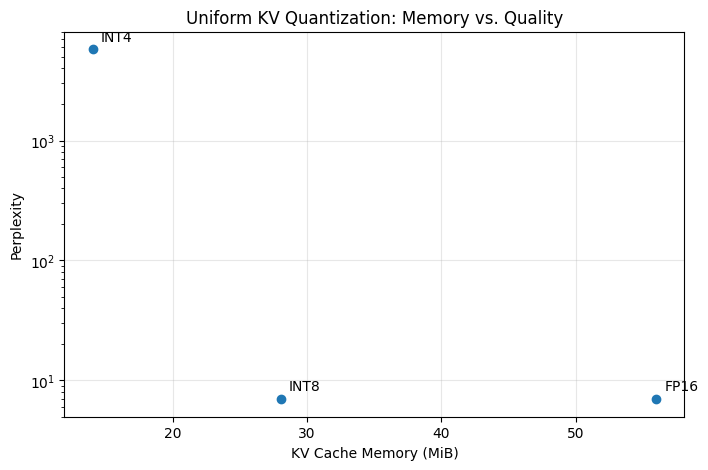

In [11]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))

plt.scatter(
    tradeoff_df["KV Memory (MiB)"],
    tradeoff_df["PPL"]
)

for _, row in tradeoff_df.iterrows():

    plt.annotate(
        row["Precision"],
        (
            row["KV Memory (MiB)"],
            row["PPL"]
        ),
        xytext=(6, 6),
        textcoords="offset points"
    )


plt.xlabel("KV Cache Memory (MiB)")
plt.ylabel("Perplexity")
plt.title("Uniform KV Quantization: Memory vs. Quality")

# INT4 is several orders of magnitude worse,
# so logarithmic scale makes all three visible.
plt.yscale("log")

plt.grid(alpha=0.3)

plt.show()

Memory–Quality Tradeoff

Uniform KV-cache quantization reveals a strong tradeoff between memory reduction and model quality. FP16 requires 56 MiB of KV-cache storage for the 2048-token sequence and achieves a perplexity of 6.9736. Uniform INT8 reduces the theoretical cache size to 28.03 MiB, a 49.95% memory saving, while increasing perplexity by only 0.097%.

Uniform INT4 reduces the theoretical cache size further to 14.03 MiB, corresponding to a 74.95% memory saving, but causes severe degradation: perplexity increases to 5772.08, approximately 827.7× the FP16 value.

These results suggest that INT8 is a strong uniform compression baseline, while applying INT4 uniformly is too aggressive with the current quantization method. This motivates a mixed-precision strategy in which lower precision is applied selectively to some KV-cache pages while sensitive or important pages remain at higher precision.

The current results are based on a 2048-token WikiText-2 sequence and therefore serve as an intermediate experimental result rather than the final full-dataset evaluation.

#7. Save results

In [12]:
# ============================================================
# CELL 7 — Save Cache-Aware Quantization Results
# ============================================================

import json


# --------------------------------------------------
# Final summary
# --------------------------------------------------

cache_quality_summary = {
    "model": MODEL_ID,

    "evaluation_dataset": "WikiText-2 test",
    "evaluation_tokens": SANITY_EVAL_TOKENS,
    "target_tokens": result_fp16_2048["Target_Tokens"],

    "page_size": PAGE_SIZE,

    "cache_evaluation":
        "page-wise autoregressive cache-aware evaluation",

    "quantization_method":
        "symmetric per-layer, per-page, per-K/V quantization",

    # FP16
    "fp16_ppl":
        result_fp16_2048["PPL"],

    "fp16_memory_mib":
        56.0,

    # INT8
    "int8_ppl":
        result_int8_2048["PPL"],

    "int8_delta_ppl":
        result_int8_2048["PPL"]
        - result_fp16_2048["PPL"],

    "int8_relative_ppl_change_percent":
        100 * (
            result_int8_2048["PPL"]
            / result_fp16_2048["PPL"]
            - 1
        ),

    "int8_memory_mib":
        28.027344,

    "int8_memory_saving_percent":
        49.951172,

    # INT4
    "int4_ppl":
        result_int4_2048["PPL"],

    "int4_delta_ppl":
        result_int4_2048["PPL"]
        - result_fp16_2048["PPL"],

    "int4_ppl_ratio_vs_fp16":
        result_int4_2048["PPL"]
        / result_fp16_2048["PPL"],

    "int4_memory_mib":
        14.027344,

    "int4_memory_saving_percent":
        74.951172
}


# --------------------------------------------------
# Print summary
# --------------------------------------------------

print("Cache-Aware Quantization Summary")
print("--------------------------------")

for key, value in cache_quality_summary.items():
    print(f"{key}: {value}")


# --------------------------------------------------
# Save tables
# --------------------------------------------------

sanity_results_df.to_csv(
    "cache_quantization_256_sanity.csv",
    index=False
)

results_2048_df.to_csv(
    "cache_quantization_2048_quality.csv",
    index=False
)

tradeoff_df.to_csv(
    "cache_quantization_memory_quality_tradeoff.csv",
    index=False
)


# --------------------------------------------------
# Save JSON summary
# --------------------------------------------------

with open(
    "cache_quantization_summary.json",
    "w"
) as f:

    json.dump(
        cache_quality_summary,
        f,
        indent=4
    )


print("\nSaved:")
print("  cache_quantization_256_sanity.csv")
print("  cache_quantization_2048_quality.csv")
print("  cache_quantization_memory_quality_tradeoff.csv")
print("  cache_quantization_summary.json")

Cache-Aware Quantization Summary
--------------------------------
model: Qwen/Qwen2.5-1.5B
evaluation_dataset: WikiText-2 test
evaluation_tokens: 2048
target_tokens: 2047
page_size: 16
cache_evaluation: page-wise autoregressive cache-aware evaluation
quantization_method: symmetric per-layer, per-page, per-K/V quantization
fp16_ppl: 6.973643281865264
fp16_memory_mib: 56.0
int8_ppl: 6.980422934522596
int8_delta_ppl: 0.006779652657332491
int8_relative_ppl_change_percent: 0.0972182313219605
int8_memory_mib: 28.027344
int8_memory_saving_percent: 49.951172
int4_ppl: 5772.075090327577
int4_delta_ppl: 5765.101447045711
int4_ppl_ratio_vs_fp16: 827.6986443137511
int4_memory_mib: 14.027344
int4_memory_saving_percent: 74.951172

Saved:
  cache_quantization_256_sanity.csv
  cache_quantization_2048_quality.csv
  cache_quantization_memory_quality_tradeoff.csv
  cache_quantization_summary.json
